# Stable Facial Region Masks - NON-OVERLAPPING VERSION
This notebook creates stable, non-overlapping region masks with exact polygon boundaries (no smoothing).

## Strategy:
1. Extract landmarks and calculate median positions
2. Define regions as exact polygons (no convex hull smoothing)
3. Enforce non-overlapping by priority order
4. Generate mutually exclusive binary masks

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import dlib
from collections import defaultdict
import pickle
import warnings
warnings.filterwarnings('ignore')

## Configuration

In [4]:
BASE_DIR = Path('/Users/mac/Documents/FMT/original-faces')
VIDEO_ID = '000'
VIDEO_PATH = BASE_DIR / VIDEO_ID

# Initialize dlib
detector = dlib.get_frontal_face_detector()
PREDICTOR_PATH = 'shape_predictor_68_face_landmarks.dat'

if not Path(PREDICTOR_PATH).exists():
    print("Please download shape_predictor_68_face_landmarks.dat from:")
    print("http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2")
else:
    predictor = dlib.shape_predictor(PREDICTOR_PATH)
    print("Predictor loaded successfully")

Predictor loaded successfully


## Define Non-Overlapping Regions with Priority
Priority determines which region "wins" in case of potential overlap.
Higher priority = assigned first (more important regions)

In [5]:
# Region definitions: (indices, priority)
# Priority: 1 = highest (assigned first), higher numbers = lower priority
REGION_DEFINITIONS = {
    'right_eye': {
        'indices': list(range(36, 42)),
        'priority': 1,
        'color': (255, 0, 0)
    },
    'left_eye': {
        'indices': list(range(42, 48)),
        'priority': 1,
        'color': (255, 0, 0)
    },
    'inner_mouth': {
        'indices': list(range(60, 68)),
        'priority': 2,
        'color': (255, 200, 0)
    },
    'outer_mouth': {
        'indices': list(range(48, 60)),
        'priority': 3,
        'color': (255, 255, 0)
    },
    'nose_base': {
        'indices': list(range(31, 36)),
        'priority': 4,
        'color': (0, 0, 255)
    },
    'nose_bridge': {
        'indices': list(range(27, 31)),
        'priority': 5,
        'color': (0, 0, 200)
    },
    'right_eyebrow': {
        'indices': list(range(17, 22)),
        'priority': 6,
        'color': (0, 255, 0)
    },
    'left_eyebrow': {
        'indices': list(range(22, 27)),
        'priority': 6,
        'color': (0, 255, 0)
    },
    'right_cheek': {
        'indices': [1, 2, 3, 31, 39, 40, 41, 36],
        'priority': 7,
        'color': (255, 0, 255)
    },
    'left_cheek': {
        'indices': [13, 14, 15, 35, 42, 43, 44, 45],
        'priority': 7,
        'color': (255, 0, 255)
    },
    'forehead': {
        'indices': [17, 18, 19, 24, 25, 26],
        'priority': 8,
        'color': (0, 255, 255)
    },
    'chin': {
        'indices': list(range(5, 12)),
        'priority': 9,
        'color': (128, 128, 128)
    },
    'jawline': {
        'indices': list(range(0, 17)),
        'priority': 10,
        'color': (192, 192, 192)
    }
}

print(f"Defined {len(REGION_DEFINITIONS)} regions with priorities")

Defined 13 regions with priorities


## Extract Landmarks

In [6]:
import dlib

detector = dlib.get_frontal_face_detector()

predictor_path = "shape_predictor_68_face_landmarks.dat"
predictor = dlib.shape_predictor(predictor_path)


In [7]:
def extract_landmarks(image_path, detector, predictor):
    """Extract 68 facial landmarks from an image."""
    img = cv2.imread(str(image_path))
    if img is None:
        return None, None
    
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    faces = detector(gray, 1)
    
    if len(faces) == 0:
        return None, img
    
    landmarks = predictor(gray, faces[0])
    coords = np.array([[p.x, p.y] for p in landmarks.parts()])
    
    return coords, img

def collect_all_landmarks(video_path, detector, predictor):
    """Collect landmarks from all frames."""
    image_files = sorted(list(video_path.glob('*.png')) + list(video_path.glob('*.jpg')))
    
    all_landmarks = []
    valid_images = []
    
    print(f"Processing {len(image_files)} frames...")
    for img_path in image_files:
        landmarks, img = extract_landmarks(img_path, detector, predictor)
        if landmarks is not None:
            all_landmarks.append(landmarks)
            valid_images.append(img_path)
    
    print(f"Extracted landmarks from {len(all_landmarks)} frames")
    return np.array(all_landmarks), valid_images

# Extract landmarks
all_landmarks, valid_images = collect_all_landmarks(VIDEO_PATH, detector, predictor)
print(f"Shape: {all_landmarks.shape}")

Processing 128 frames...
Extracted landmarks from 128 frames
Shape: (128, 68, 2)


## Calculate Median Landmarks

In [8]:
median_landmarks = np.median(all_landmarks, axis=0).astype(np.int32)
print(f"Median landmarks shape: {median_landmarks.shape}")

# Get image shape
first_frame = cv2.imread(str(valid_images[0]))
image_shape = first_frame.shape
print(f"Image shape: {image_shape}")

Median landmarks shape: (68, 2)
Image shape: (256, 256, 3)


## Generate Non-Overlapping Masks
**Key: No smoothing, exact polygons, priority-based assignment**

In [9]:
def create_exact_polygon_mask(landmarks, indices, image_shape):
    """Create mask with EXACT polygon boundary - NO SMOOTHING."""
    mask = np.zeros(image_shape[:2], dtype=np.uint8)
    points = landmarks[indices].astype(np.int32)
    
    # Fill polygon with exact points (no convex hull)
    cv2.fillPoly(mask, [points], 255)
    
    return mask

def generate_non_overlapping_masks(median_landmarks, region_definitions, image_shape):
    """Generate non-overlapping masks by priority."""
    # Sort regions by priority
    sorted_regions = sorted(region_definitions.items(), 
                           key=lambda x: x[1]['priority'])
    
    region_masks = {}
    occupied_mask = np.zeros(image_shape[:2], dtype=np.uint8)
    
    for region_name, region_info in sorted_regions:
        # Create mask for this region
        mask = create_exact_polygon_mask(median_landmarks, 
                                        region_info['indices'], 
                                        image_shape)
        
        # Remove already occupied pixels
        mask = cv2.bitwise_and(mask, cv2.bitwise_not(occupied_mask))
        
        # Update occupied mask
        occupied_mask = cv2.bitwise_or(occupied_mask, mask)
        
        region_masks[region_name] = mask
        
        pixel_count = np.sum(mask > 0)
        print(f"{region_name:<20} Priority:{region_info['priority']:<3} Pixels:{pixel_count:>6}")
    
    return region_masks, occupied_mask

# Generate masks
print("\n=== Generating Non-Overlapping Masks ===")
region_masks, occupied_mask = generate_non_overlapping_masks(
    median_landmarks, REGION_DEFINITIONS, image_shape
)

total_pixels = np.sum(occupied_mask > 0)
print(f"\nTotal covered pixels: {total_pixels}")


=== Generating Non-Overlapping Masks ===
right_eye            Priority:1   Pixels:   298
left_eye             Priority:1   Pixels:   275
inner_mouth          Priority:2   Pixels:   286
outer_mouth          Priority:3   Pixels:  1355
nose_base            Priority:4   Pixels:   116
nose_bridge          Priority:5   Pixels:    62
right_eyebrow        Priority:6   Pixels:   571
left_eyebrow         Priority:6   Pixels:   619
right_cheek          Priority:7   Pixels:  4333
left_cheek           Priority:7   Pixels:  2710
forehead             Priority:8   Pixels:  1640
chin                 Priority:9   Pixels:  3096
jawline              Priority:10  Pixels: 13611

Total covered pixels: 28972


## Verify No Overlaps

In [10]:
# Check for overlaps
print("\n=== Overlap Verification ===")
overlap_found = False

region_names = list(region_masks.keys())
for i, name1 in enumerate(region_names):
    for name2 in region_names[i+1:]:
        overlap = cv2.bitwise_and(region_masks[name1], region_masks[name2])
        overlap_pixels = np.sum(overlap > 0)
        
        if overlap_pixels > 0:
            print(f"⚠️  Overlap between {name1} and {name2}: {overlap_pixels} pixels")
            overlap_found = True

if not overlap_found:
    print("✅ No overlaps detected - all regions are mutually exclusive")

# Check total pixel sum
sum_check = sum(np.sum(mask > 0) for mask in region_masks.values())
print(f"\nSum of individual regions: {sum_check}")
print(f"Total occupied pixels:     {total_pixels}")
print(f"Match: {sum_check == total_pixels}")


=== Overlap Verification ===
✅ No overlaps detected - all regions are mutually exclusive

Sum of individual regions: 28972
Total occupied pixels:     28972
Match: True


## Visualize All Masks

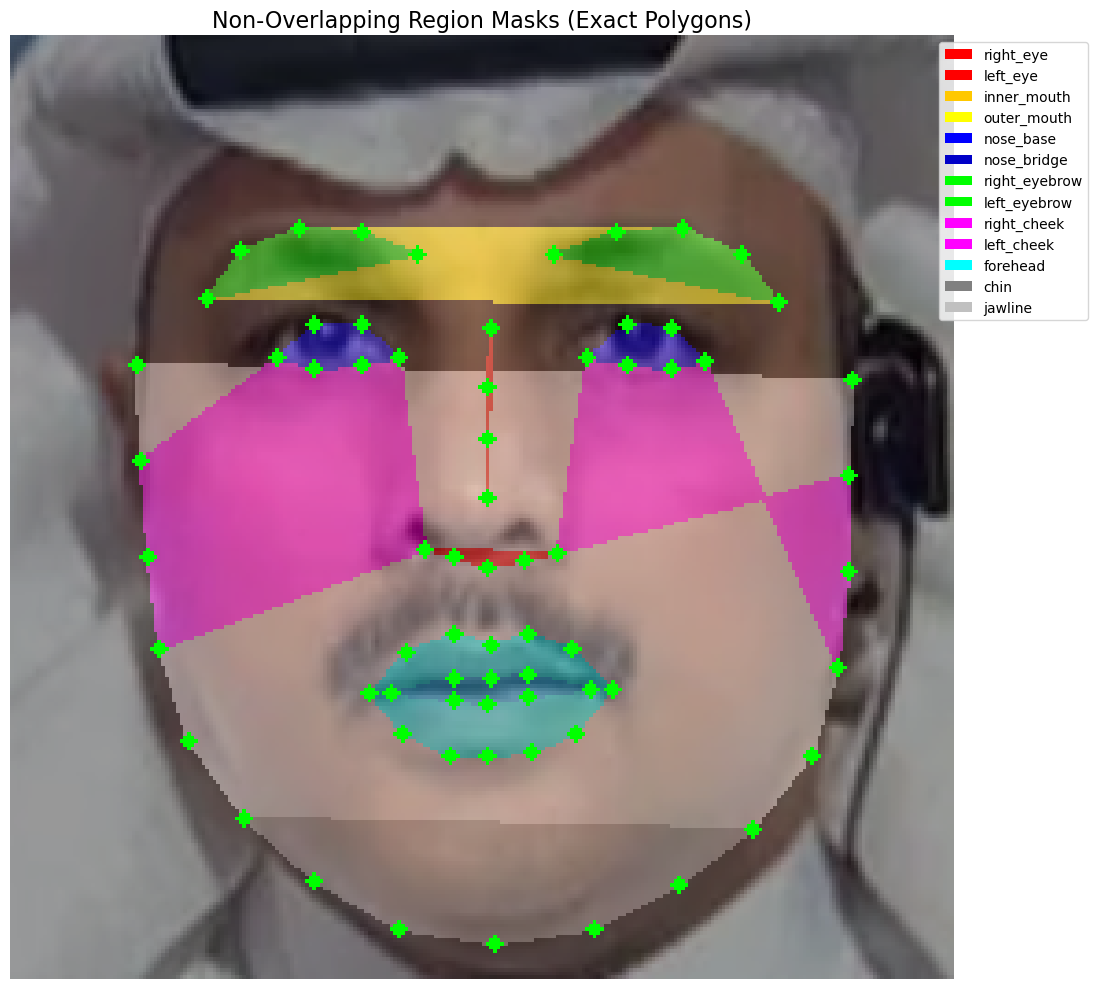

In [15]:
def visualize_all_masks(image, masks, region_definitions, median_landmarks):
    """Visualize all non-overlapping masks."""
    overlay = image.copy()
    combined_mask = np.zeros_like(image)
    
    for region_name, mask in masks.items():
        color = region_definitions[region_name]['color']
        colored_mask = np.zeros_like(image)
        colored_mask[mask > 0] = color
        combined_mask = cv2.add(combined_mask, colored_mask)
    
    result = cv2.addWeighted(overlay, 0.6, combined_mask, 0.4, 0)
    
    # Draw median landmarks
    for x, y in median_landmarks:
        cv2.circle(result, (x, y), 2, (0, 255, 0), -1)
    
    return result

# Visualize
first_frame_vis = visualize_all_masks(first_frame, region_masks, 
                                      REGION_DEFINITIONS, median_landmarks)

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(first_frame_vis, cv2.COLOR_BGR2RGB))
plt.title('Non-Overlapping Region Masks (Exact Polygons)', fontsize=16)
plt.axis('off')

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=np.array(info['color'])/255, label=name) 
    for name, info in REGION_DEFINITIONS.items()
]
plt.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))

plt.tight_layout()
plt.show()

## Individual Region Visualization

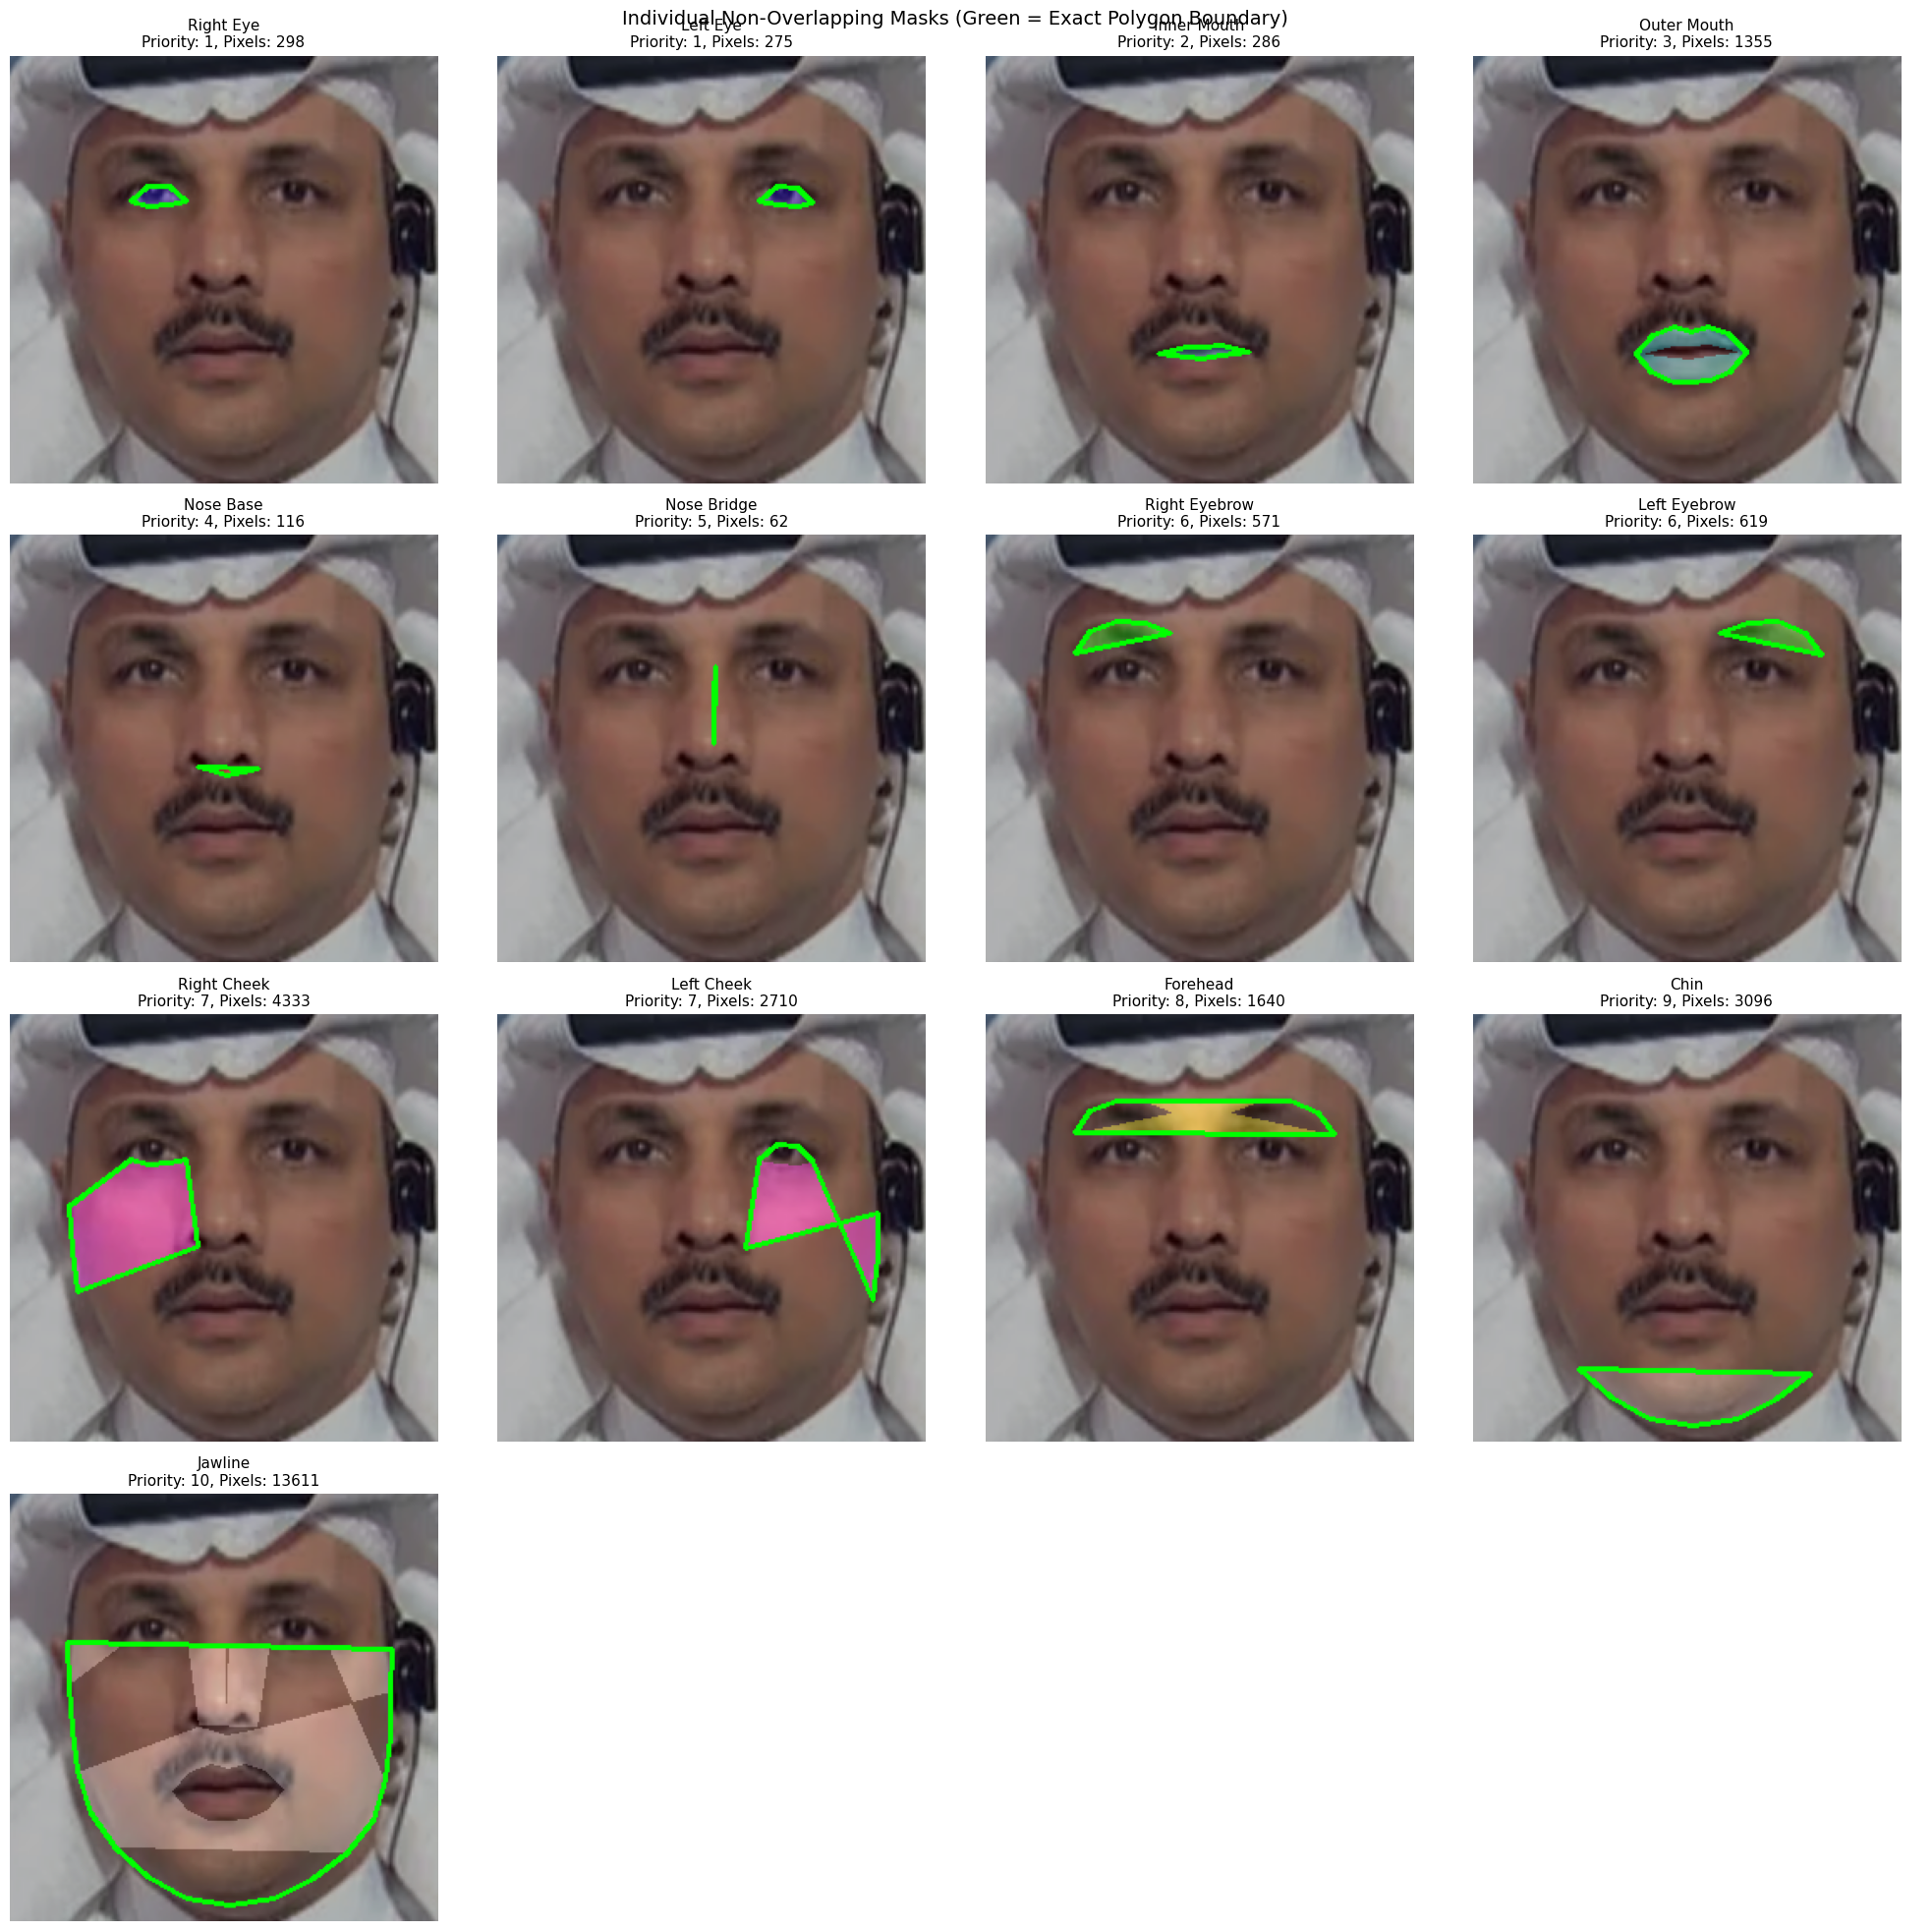

In [16]:
n_regions = len(region_masks)
n_cols = 4
n_rows = (n_regions + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5*n_rows))
axes = axes.flatten()

for idx, (region_name, mask) in enumerate(region_masks.items()):
    ax = axes[idx]
    
    vis_image = first_frame.copy()
    colored_mask = np.zeros_like(vis_image)
    color = REGION_DEFINITIONS[region_name]['color']
    colored_mask[mask > 0] = color
    result = cv2.addWeighted(vis_image, 0.7, colored_mask, 0.3, 0)
    
    # Draw polygon boundary
    indices = REGION_DEFINITIONS[region_name]['indices']
    points = median_landmarks[indices].astype(np.int32)
    cv2.polylines(result, [points], True, (0, 255, 0), 2)
    
    ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    priority = REGION_DEFINITIONS[region_name]['priority']
    pixel_count = np.sum(mask > 0)
    ax.set_title(f'{region_name.replace("_", " ").title()}\nPriority: {priority}, Pixels: {pixel_count}', 
                fontsize=11)
    ax.axis('off')

for idx in range(n_regions, len(axes)):
    axes[idx].axis('off')

plt.suptitle('Individual Non-Overlapping Masks (Green = Exact Polygon Boundary)', fontsize=14)
plt.tight_layout()
plt.show()

## Test Stability Across Frames

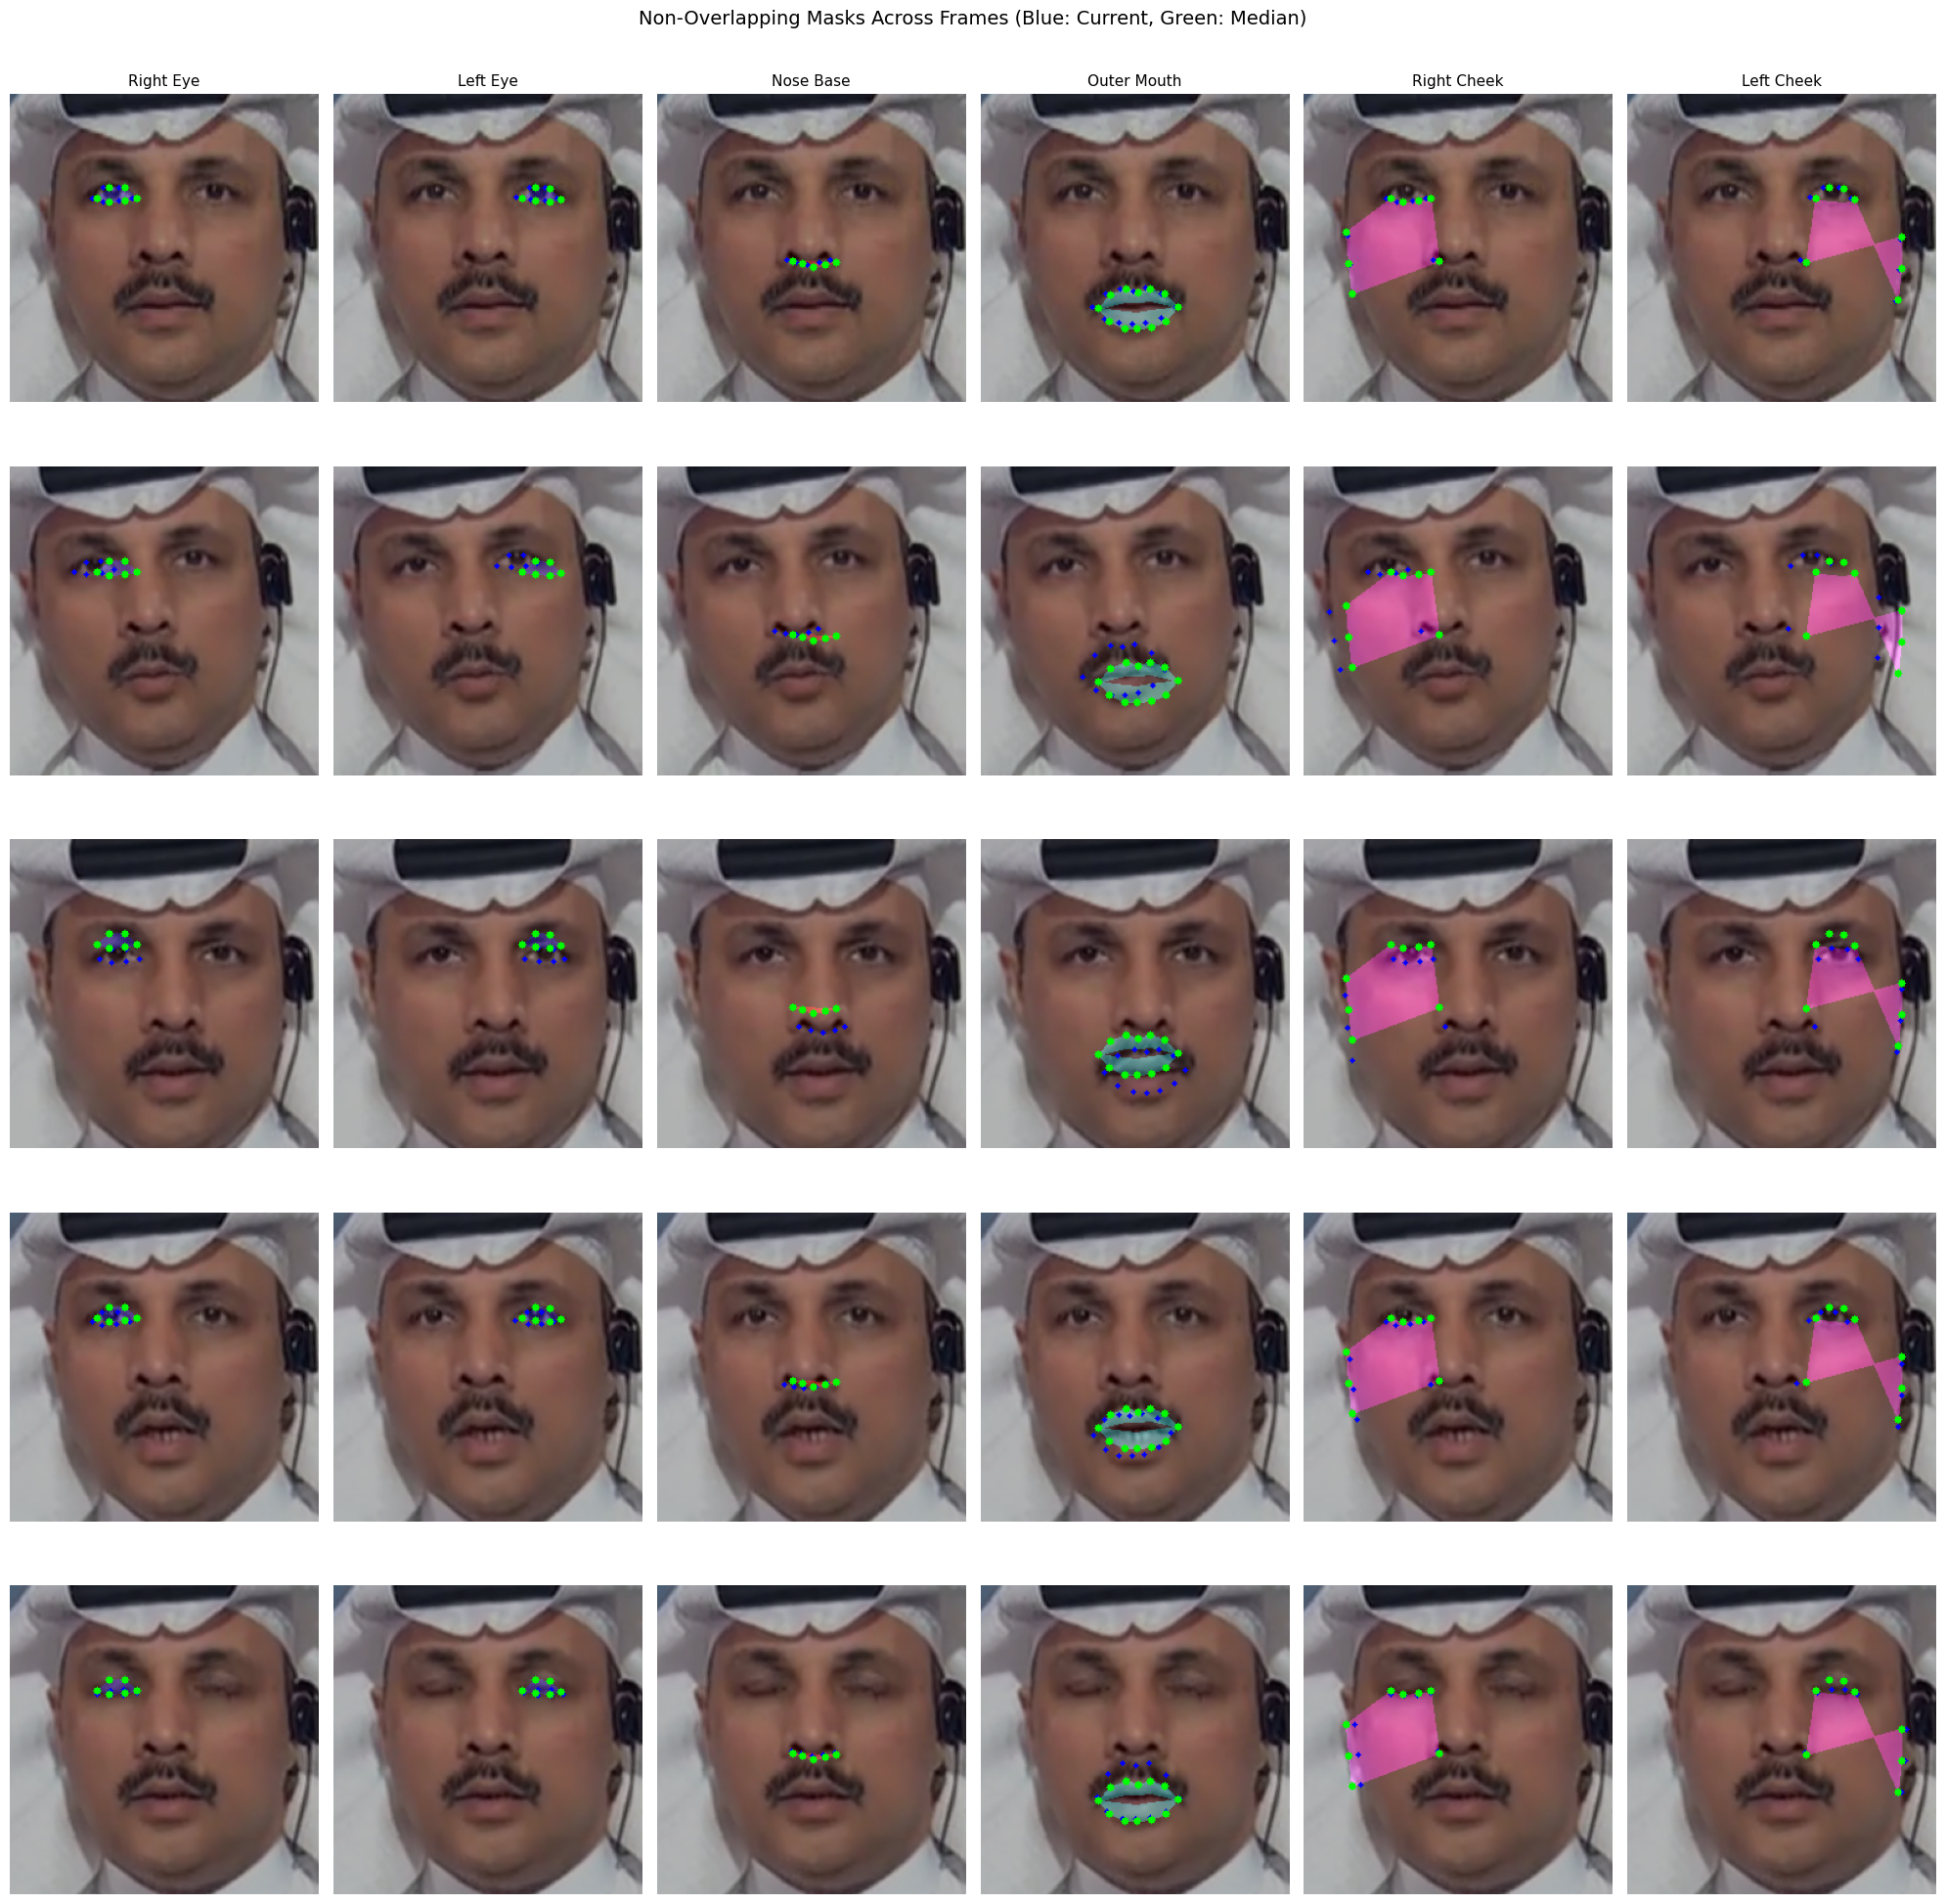

In [17]:
n_frames = len(valid_images)
test_frame_indices = [0, n_frames//4, n_frames//2, 3*n_frames//4, n_frames-1]

key_regions = ['right_eye', 'left_eye', 'nose_base', 'outer_mouth', 'right_cheek', 'left_cheek']

fig, axes = plt.subplots(len(test_frame_indices), len(key_regions), 
                         figsize=(20, 4*len(test_frame_indices)))

for row_idx, frame_idx in enumerate(test_frame_indices):
    frame = cv2.imread(str(valid_images[frame_idx]))
    current_landmarks = all_landmarks[frame_idx]
    
    for col_idx, region_name in enumerate(key_regions):
        ax = axes[row_idx, col_idx]
        
        vis_image = frame.copy()
        mask = region_masks[region_name]
        colored_mask = np.zeros_like(vis_image)
        color = REGION_DEFINITIONS[region_name]['color']
        colored_mask[mask > 0] = color
        result = cv2.addWeighted(vis_image, 0.7, colored_mask, 0.3, 0)
        
        # Draw current frame landmarks (blue)
        indices = REGION_DEFINITIONS[region_name]['indices']
        for idx in indices:
            x, y = current_landmarks[idx]
            cv2.circle(result, (int(x), int(y)), 2, (255, 0, 0), -1)
        
        # Draw median landmarks (green)
        for idx in indices:
            x, y = median_landmarks[idx]
            cv2.circle(result, (int(x), int(y)), 3, (0, 255, 0), -1)
        
        ax.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
        
        if row_idx == 0:
            ax.set_title(region_name.replace('_', ' ').title(), fontsize=11)
        if col_idx == 0:
            ax.set_ylabel(f'Frame {frame_idx}', fontsize=11)
        ax.axis('off')

plt.suptitle('Non-Overlapping Masks Across Frames (Blue: Current, Green: Median)', 
             fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

## Coverage Statistics

In [18]:
def calculate_mask_coverage(landmarks, mask, region_indices):
    """Calculate percentage of landmarks within mask."""
    points = landmarks[region_indices]
    inside_count = 0
    
    for x, y in points:
        if 0 <= int(y) < mask.shape[0] and 0 <= int(x) < mask.shape[1]:
            if mask[int(y), int(x)] > 0:
                inside_count += 1
    
    return inside_count / len(points) * 100

coverage_stats = defaultdict(list)

for frame_idx, landmarks in enumerate(all_landmarks):
    for region_name, mask in region_masks.items():
        indices = REGION_DEFINITIONS[region_name]['indices']
        coverage = calculate_mask_coverage(landmarks, mask, indices)
        coverage_stats[region_name].append(coverage)

print("\n=== Non-Overlapping Mask Coverage ===")
print(f"{'Region':<20} {'Mean':<10} {'Min':<10} {'Max':<10} {'Std':<10}")
print("-" * 60)

for region_name in sorted(coverage_stats.keys()):
    coverages = coverage_stats[region_name]
    print(f"{region_name:<20} {np.mean(coverages):>6.2f}%   "
          f"{np.min(coverages):>6.2f}%   {np.max(coverages):>6.2f}%   "
          f"{np.std(coverages):>6.2f}%")


=== Non-Overlapping Mask Coverage ===
Region               Mean       Min        Max        Std       
------------------------------------------------------------
chin                  37.39%     0.00%    85.71%    30.99%
forehead               3.65%     0.00%    33.33%     7.78%
inner_mouth           39.16%     0.00%    87.50%    22.88%
jawline               19.07%     0.00%    41.18%     9.38%
left_cheek            20.21%     0.00%    75.00%    16.02%
left_eye              37.37%     0.00%    83.33%    18.25%
left_eyebrow          39.53%     0.00%    80.00%    22.29%
nose_base             29.69%     0.00%   100.00%    25.49%
nose_bridge           10.55%     0.00%   100.00%    26.26%
outer_mouth           45.96%     0.00%   100.00%    24.23%
right_cheek           35.74%     0.00%    87.50%    24.39%
right_eye             41.80%     0.00%   100.00%    19.54%
right_eyebrow         36.25%     0.00%   100.00%    29.13%


## Save Masks (Later After Refinement)

In [ ]:
output_data = {
    'video_id': VIDEO_ID,
    'median_landmarks': median_landmarks,
    'region_masks': region_masks,
    'region_definitions': REGION_DEFINITIONS,
    'image_shape': image_shape,
    'coverage_stats': dict(coverage_stats),
    'non_overlapping': True
}

output_path = f'/mnt/user-data/outputs/non_overlapping_masks_{VIDEO_ID}.pkl'
with open(output_path, 'wb') as f:
    pickle.dump(output_data, f)

print(f"\nSaved to: {output_path}")

# Save individual masks
for region_name, mask in region_masks.items():
    cv2.imwrite(f'/mnt/user-data/outputs/non_overlap_mask_{region_name}.png', mask)

print(f"Saved {len(region_masks)} individual masks")

## Summary

**Use Cases:**
- Region-specific analysis without ambiguity
- Partitioning face into non-overlapping zones
- Precise boundary detection
- Mutually exclusive feature extraction